# Projeto final - cultura do scroll e déficit de atenção

Dados da TIC Kids Online Brasil 2024, do Cetic.br (tabelas B2, C7, E3A e G17). Pra rodar tem que subir o Dados_cetic_tratados.csv no Colab.

Significado das siglas:
- TIC = Tecnologias de Informação e Comunicação
- Cetic.br = Centro Regional de Estudos para o Desenvolvimento da Sociedade da Informação
- B2 = tabela de atividades feitas na internet
- C7 = tabela de uso das plataformas (TikTok, Instagram, YouTube, WhatsApp)
- E3A = tabela de orientação dos pais ou responsáveis
- G17 = tabela de uso excessivo da internet nos últimos 12 meses (só 11 a 17 anos)
- Classe AB / C / DE = classes econômicas: AB são as mais altas, C a intermediária e DE as mais baixas
- IQR = intervalo interquartil

In [ ]:
# AQUI IMPORTA AS BIBLIOTECAS
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# AQUI DEIXA OS GRÁFICOS COM FUNDO BRANCO E TAMANHO PADRÃO
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

## Limpeza dos dados

In [ ]:
# AQUI LÊ A BASE (CADA LINHA É UM GRUPO E OS VALORES ESTÃO EM %)
df = pd.read_csv('Dados_cetic_tratados.csv')
print(df.shape)
df.head()

(20, 38)


,recorte_tipo,recorte,redes_diario,redes_mais1x_dia,videos_diario,videos_mais1x_dia,jogos_diario,escolar_diario,escolar_semanal_ou_mais,escolar_nao_realiza,...,med_olham_celular,med_regras_celular,med_deixam_sem_celular,med_ensinam_seguranca,med_conversam,med_sentam_junto,med_restritiva_media,med_ativa_media,gap_videos_menos_escolar,gap_redes_menos_escolar
0,Total,Total,67.0,54.0,66.0,43.0,62.0,52.0,74.0,14.0,...,43.0,39.0,22.0,57.0,45.0,34.0,34.7,45.3,14.0,15.0
1,Área,Rural,66.0,51.0,54.0,30.0,55.0,52.0,75.0,16.0,...,45.0,36.0,23.0,58.0,47.0,39.0,34.7,48.0,2.0,14.0
2,Área,Urbana,67.0,54.0,69.0,46.0,63.0,52.0,74.0,14.0,...,42.0,39.0,21.0,57.0,45.0,34.0,34.0,45.3,17.0,15.0
3,Região,Centro-Oeste,68.0,50.0,64.0,44.0,69.0,50.0,71.0,17.0,...,39.0,35.0,16.0,57.0,54.0,33.0,30.0,48.0,14.0,18.0
4,Região,Nordeste,68.0,53.0,59.0,38.0,59.0,53.0,75.0,15.0,...,39.0,34.0,20.0,54.0,43.0,32.0,31.0,43.0,6.0,15.0


In [ ]:
# AQUI MOSTRA QUANTAS COLUNAS SÃO TEXTO E QUANTAS SÃO NÚMERO
print(df.dtypes.value_counts())

float64    36
object      2
Name: count, dtype: int64


In [ ]:
# AQUI TIRA OS ESPAÇOS SOBRANDO DOS TEXTOS
df['recorte_tipo'] = df['recorte_tipo'].str.strip()
df['recorte'] = df['recorte'].str.strip()

# AQUI COLOCA O NOME DAS CLASSES SOCIAIS
df['recorte'] = df['recorte'].replace({'AB': 'Classe AB (mais alta)', 'C': 'Classe C (intermediária)', 'DE': 'Classe DE (mais baixa)'})

# AQUI VÊ SE TEM LINHA REPETIDA E QUANTOS GRUPOS TEM DE CADA TIPO
print('duplicadas:', df.duplicated().sum())
print(df['recorte_tipo'].value_counts())

duplicadas: 0
recorte_tipo
Região                           5
Faixa etária                     4
Classe social                    3
Escolaridade dos responsáveis    3
Área                             2
Sexo                             2
Total                            1
Name: count, dtype: int64


In [ ]:
# AQUI VÊ SE AS PORCENTAGENS ESTÃO ENTRE 0 E 100 (AS COLUNAS GAP PODEM SER NEGATIVAS)
colunas_num = df.select_dtypes(include='number').columns
problemas = 0
for col in colunas_num:
    if col.startswith('gap_'):
        continue
    if df[col].min() < 0 or df[col].max() > 100:
        print('problema em', col)
        problemas = problemas + 1
print('colunas com problema:', problemas)

colunas com problema: 0


In [ ]:
# AQUI CONTA OS VALORES VAZIOS E MOSTRA EM QUAIS GRUPOS ELES ESTÃO
nulos = df.isnull().sum()
print(nulos[nulos > 0])
df[df.isnull().any(axis=1)][['recorte_tipo', 'recorte']]

g17_comer_dormir             1
g17_sentiu_mal               1
g17_sem_interesse            1
g17_menos_tempo_licao        1
g17_nao_conseguiu_reduzir    1
g17_nenhuma                  1
g17_ns_nr                    1
g17_indice_medio_5itens      1
g17_ao_menos_uma_aprox       1
med_olham_celular            3
med_regras_celular           3
med_deixam_sem_celular       3
med_ensinam_seguranca        3
med_conversam                3
med_sentam_junto             3
med_restritiva_media         3
med_ativa_media              3
dtype: int64


,recorte_tipo,recorte
16,Faixa etária,9 a 10 anos
17,Escolaridade dos responsáveis,Até Fundamental I
18,Escolaridade dos responsáveis,Fundamental II
19,Escolaridade dos responsáveis,Médio ou mais


Os vazios são de 9 a 10 anos no G17, porque essa pergunta só é feita pra quem tem de 11 a 17, e da mediação dos pais por escolaridade, que a tabela não tem. Resolvemos deixar vazio mesmo, colocar 0 ia parecer que essas crianças não têm problema nenhum.

In [ ]:
# AQUI REFAZ AS CONTAS DAS COLUNAS QUE A GENTE CRIOU PRA VER SE BATEM (PODE TER DIFERENÇA DE ARREDONDAMENTO)
indice = df[['g17_comer_dormir', 'g17_sentiu_mal', 'g17_sem_interesse', 'g17_menos_tempo_licao', 'g17_nao_conseguiu_reduzir']].mean(axis=1)
print('g17_indice_medio_5itens:', round((df['g17_indice_medio_5itens'] - indice).abs().max(), 2))

ao_menos_uma = 100 - df['g17_nenhuma'] - df['g17_ns_nr']
print('g17_ao_menos_uma_aprox:', round((df['g17_ao_menos_uma_aprox'] - ao_menos_uma).abs().max(), 2))

restritiva = df[['med_olham_celular', 'med_regras_celular', 'med_deixam_sem_celular']].mean(axis=1)
print('med_restritiva_media:', round((df['med_restritiva_media'] - restritiva).abs().max(), 2))

ativa = df[['med_ensinam_seguranca', 'med_conversam', 'med_sentam_junto']].mean(axis=1)
print('med_ativa_media:', round((df['med_ativa_media'] - ativa).abs().max(), 2))

gap1 = df['videos_diario'] - df['escolar_diario']
print('gap_videos_menos_escolar:', round((df['gap_videos_menos_escolar'] - gap1).abs().max(), 2))

gap2 = df['redes_diario'] - df['escolar_diario']
print('gap_redes_menos_escolar:', round((df['gap_redes_menos_escolar'] - gap2).abs().max(), 2))

g17_indice_medio_5itens: 0.0
g17_ao_menos_uma_aprox: 0.0
med_restritiva_media: 0.03
med_ativa_media: 0.03
gap_videos_menos_escolar: 0.0
gap_redes_menos_escolar: 0.0


Tudo bateu, a diferença de 0,03 é só arredondamento.

Também conferimos alguns valores com as tabelas do site do Cetic. Lá os números vêm separados por frequência, então somamos do mesmo jeito que na base.

In [ ]:
# AQUI FICAM OS VALORES COPIADOS DO SITE DO CETIC (B2 E C7 SOMANDO AS FREQUÊNCIAS DIÁRIAS, E3A SOMANDO SEMPRE + QUASE SEMPRE)
site = [
    ['Total', 'redes_diario', 54 + 13],
    ['Total', 'videos_diario', 43 + 23],
    ['Total', 'escolar_diario', 32 + 20],
    ['15 a 17 anos', 'instagram_frequente', 63 + 19],
    ['15 a 17 anos', 'whatsapp_frequente', 78 + 13],
    ['Total', 'med_regras_celular', 29 + 10],
    ['15 a 17 anos', 'med_regras_celular', 12 + 9],
    ['Total', 'g17_nao_conseguiu_reduzir', 24],
    ['Total', 'g17_nenhuma', 35],
    ['Classe AB (mais alta)', 'g17_nao_conseguiu_reduzir', 40],
    ['Classe DE (mais baixa)', 'g17_nao_conseguiu_reduzir', 20],
    ['Sul', 'g17_menos_tempo_licao', 34],
    ['Feminino', 'g17_menos_tempo_licao', 29],
]

# AQUI COMPARA CADA VALOR DO SITE COM O DA BASE
diferentes = 0
for recorte, coluna, valor_site in site:
    valor_base = df[df['recorte'] == recorte][coluna].iloc[0]
    if valor_base == valor_site:
        print('ok', recorte, coluna, valor_base)
    else:
        print('DIFERENTE', recorte, coluna, 'base:', valor_base, 'site:', valor_site)
        diferentes = diferentes + 1
print('valores diferentes:', diferentes)

ok Total redes_diario 67.0
ok Total videos_diario 66.0
ok Total escolar_diario 52.0
ok 15 a 17 anos instagram_frequente 82.0
ok 15 a 17 anos whatsapp_frequente 91.0
ok Total med_regras_celular 39.0
ok 15 a 17 anos med_regras_celular 21.0
ok Total g17_nao_conseguiu_reduzir 24.0
ok Total g17_nenhuma 35.0
ok Classe AB (mais alta) g17_nao_conseguiu_reduzir 40.0
ok Classe DE (mais baixa) g17_nao_conseguiu_reduzir 20.0
ok Sul g17_menos_tempo_licao 34.0
ok Feminino g17_menos_tempo_licao 29.0
valores diferentes: 0


In [ ]:
# AQUI TIRA A LINHA TOTAL, PORQUE ELA É A MÉDIA DO BRASIL E NÃO UM GRUPO
grupos = df[df['recorte_tipo'] != 'Total'].copy()

# AQUI PROCURA OS OUTLIERS PELO IQR EM CADA COLUNA
lista = []
for col in colunas_num:
    q1 = grupos[col].quantile(0.25)
    q3 = grupos[col].quantile(0.75)
    iqr = q3 - q1
    baixo = q1 - 1.5 * iqr
    alto = q3 + 1.5 * iqr
    for i, linha in grupos.iterrows():
        if linha[col] < baixo or linha[col] > alto:
            lista.append([col, linha['recorte_tipo'], linha['recorte'], linha[col]])

# AQUI MOSTRA QUANTOS OUTLIERS DEU E OS QUE NÃO SÃO DE FAIXA ETÁRIA
outliers = pd.DataFrame(lista, columns=['coluna', 'recorte_tipo', 'recorte', 'valor'])
print('outliers:', len(outliers))
print(outliers['recorte_tipo'].value_counts())
outliers[outliers['recorte_tipo'] != 'Faixa etária']

outliers: 51
recorte_tipo
Faixa etária                     39
Classe social                     6
Escolaridade dos responsáveis     3
Região                            2
Área                              1
Name: count, dtype: int64


,coluna,recorte_tipo,recorte,valor
6,escolar_semanal_ou_mais,Classe social,Classe AB (mais alta),86.0
8,escolar_semanal_ou_mais,Escolaridade dos responsáveis,Até Fundamental I,63.0
10,interesse_diario,Classe social,Classe AB (mais alta),77.0
12,interesse_diario,Escolaridade dos responsáveis,Até Fundamental I,35.0
20,youtube_varias_dia,Área,Rural,26.0
26,g17_comer_dormir,Escolaridade dos responsáveis,Fundamental II,23.0
27,g17_nao_conseguiu_reduzir,Classe social,Classe AB (mais alta),40.0
32,med_regras_celular,Classe social,Classe AB (mais alta),57.0
35,med_deixam_sem_celular,Classe social,Classe AB (mais alta),13.0
41,med_conversam,Região,Centro-Oeste,54.0


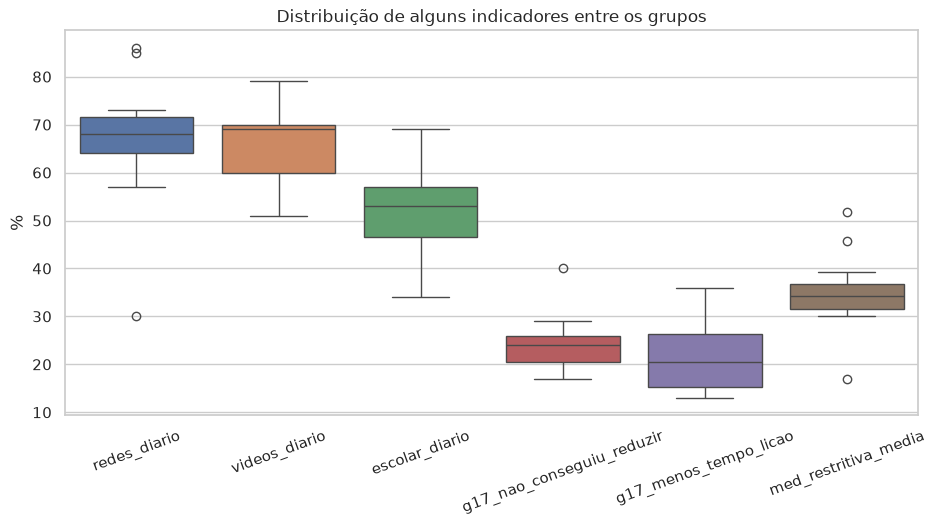

In [ ]:
# AQUI FAZ O BOXPLOT PRA VER OS OUTLIERS NO GRÁFICO
plt.figure(figsize=(11, 5))
sns.boxplot(data=grupos[['redes_diario', 'videos_diario', 'escolar_diario', 'g17_nao_conseguiu_reduzir', 'g17_menos_tempo_licao', 'med_restritiva_media']])
plt.xticks(rotation=20)
plt.ylabel('%')
plt.title('Distribuição de alguns indicadores entre os grupos')
plt.show()

Não tiramos os outliers. Quase todos são de faixa etária, e é normal criança de 9 a 10 anos usar bem menos rede social que adolescente. Os outros são diferenças reais entre grupos (o 40% da classe AB, por exemplo, a gente conferiu ali em cima). Se tirasse ia perder justamente o que a gente quer analisar.

In [ ]:
# AQUI GUARDA A LINHA DO TOTAL PRA COMPARAR COM OS GRUPOS
total = df[df['recorte_tipo'] == 'Total'].iloc[0]

# AQUI SEPARA CADA RECORTE (A IDADE FICA NA ORDEM CERTA)
ordem_idade = ['9 a 10 anos', '11 a 12 anos', '13 a 14 anos', '15 a 17 anos']
idade = grupos[grupos['recorte_tipo'] == 'Faixa etária'].set_index('recorte').loc[ordem_idade]
regiao = grupos[grupos['recorte_tipo'] == 'Região'].set_index('recorte')
classe = grupos[grupos['recorte_tipo'] == 'Classe social'].set_index('recorte')
escolaridade = grupos[grupos['recorte_tipo'] == 'Escolaridade dos responsáveis'].set_index('recorte')

print('grupos:', len(grupos))

grupos: 19


## Análise

Um cuidado: a mesma pessoa aparece em vários grupos (região, classe, sexo), então comparamos dentro de cada recorte. E a pesquisa mostra associação, não que uma coisa causa a outra.

### Pergunta 1 - uso de redes x tarefas escolares e sono

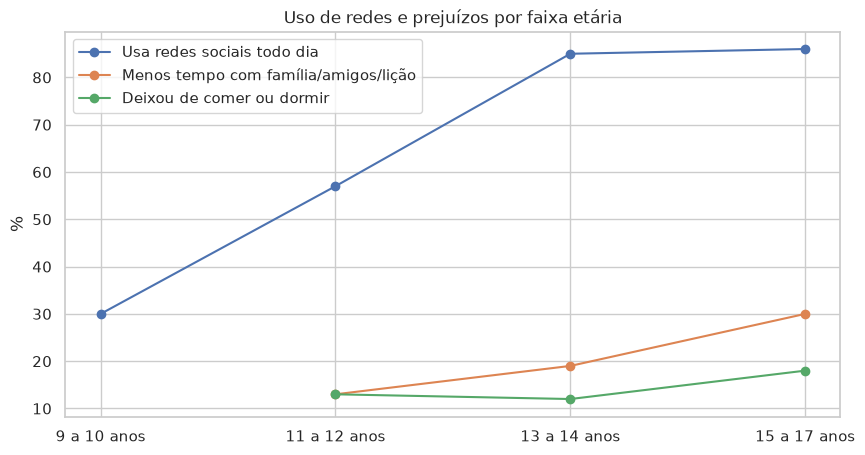

,redes_diario,g17_menos_tempo_licao,g17_comer_dormir
recorte,,,
9 a 10 anos,30.0,NaN,NaN
11 a 12 anos,57.0,13.0,13.0
13 a 14 anos,85.0,19.0,12.0
15 a 17 anos,86.0,30.0,18.0


In [ ]:
# AQUI FAZ O GRÁFICO DE LINHA DO USO DE REDES E DOS PREJUÍZOS POR IDADE
plt.plot(ordem_idade, idade['redes_diario'], marker='o', label='Usa redes sociais todo dia')
plt.plot(ordem_idade, idade['g17_menos_tempo_licao'], marker='o', label='Menos tempo com família/amigos/lição')
plt.plot(ordem_idade, idade['g17_comer_dormir'], marker='o', label='Deixou de comer ou dormir')
plt.ylabel('%')
plt.title('Uso de redes e prejuízos por faixa etária')
plt.legend()
plt.show()

idade[['redes_diario', 'g17_menos_tempo_licao', 'g17_comer_dormir']]

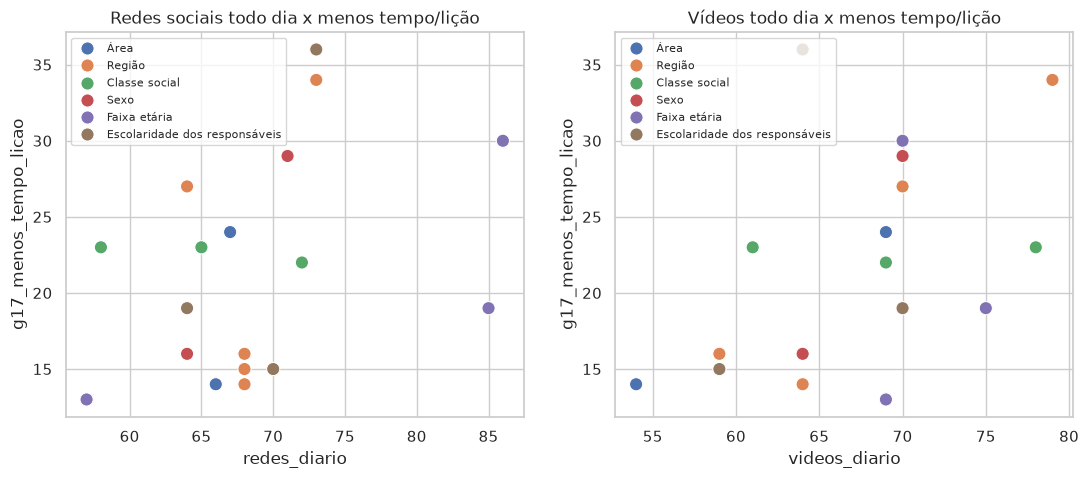

In [ ]:
# AQUI COMPARA REDES E VÍDEOS COM A PERDA DE TEMPO DE LIÇÃO (SEM 9 A 10 ANOS, QUE NÃO TEM G17)
p1 = grupos.dropna(subset=['g17_menos_tempo_licao'])

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=p1, x='redes_diario', y='g17_menos_tempo_licao', hue='recorte_tipo', s=90, ax=ax[0])
ax[0].set_title('Redes sociais todo dia x menos tempo/lição')
ax[0].legend(fontsize=8)
sns.scatterplot(data=p1, x='videos_diario', y='g17_menos_tempo_licao', hue='recorte_tipo', s=90, ax=ax[1])
ax[1].set_title('Vídeos todo dia x menos tempo/lição')
ax[1].legend(fontsize=8)
plt.show()

Quanto mais velho, mais usa rede e mais tem prejuízo. Rede todo dia vai de 30% (9 a 10 anos) pra 86% (15 a 17), e menos tempo com família/lição vai de 13% pra 30%. Nos gráficos de dispersão, vídeo parece andar mais junto com a perda de tempo de lição do que rede social. Isso a gente testa melhor lá embaixo.

### Pergunta 2 - quem tem mais dificuldade de controlar o uso

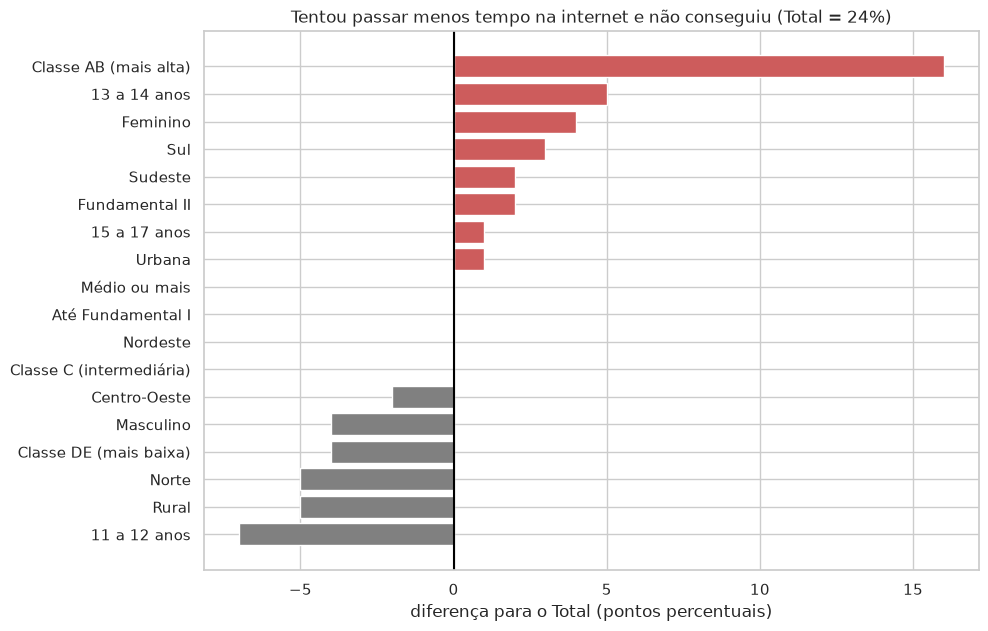

classe AB / classe DE: 2.0


In [ ]:
# AQUI CALCULA A DIFERENÇA DE CADA GRUPO PRO TOTAL DO BRASIL
p2 = grupos.dropna(subset=['g17_nao_conseguiu_reduzir']).copy()
p2['dif_total'] = p2['g17_nao_conseguiu_reduzir'] - total['g17_nao_conseguiu_reduzir']
p2 = p2.sort_values('dif_total')

# AQUI PINTA DE VERMELHO QUEM ESTÁ ACIMA DO BRASIL E DE CINZA QUEM ESTÁ ABAIXO
cores = []
for x in p2['dif_total']:
    if x > 0:
        cores.append('indianred')
    else:
        cores.append('gray')

plt.figure(figsize=(10, 7))
plt.barh(p2['recorte'], p2['dif_total'], color=cores)
plt.axvline(0, color='black')
plt.xlabel('diferença para o Total (pontos percentuais)')
plt.title('Tentou passar menos tempo na internet e não conseguiu (Total = 24%)')
plt.show()

# AQUI VÊ QUANTAS VEZES A CLASSE AB É MAIOR QUE A DE
print('classe AB / classe DE:', round(classe.loc['Classe AB (mais alta)', 'g17_nao_conseguiu_reduzir'] / classe.loc['Classe DE (mais baixa)', 'g17_nao_conseguiu_reduzir'], 1))

No Brasil 24% tentaram usar menos e não conseguiram. A classe AB (mais alta) se destaca muito, com 40%, o dobro da classe DE (mais baixa). O resto fica perto da média: 13 a 14 anos (29%) e meninas (28%) estão só um pouco acima.

### Pergunta 3 - vídeos e redes x pesquisa escolar

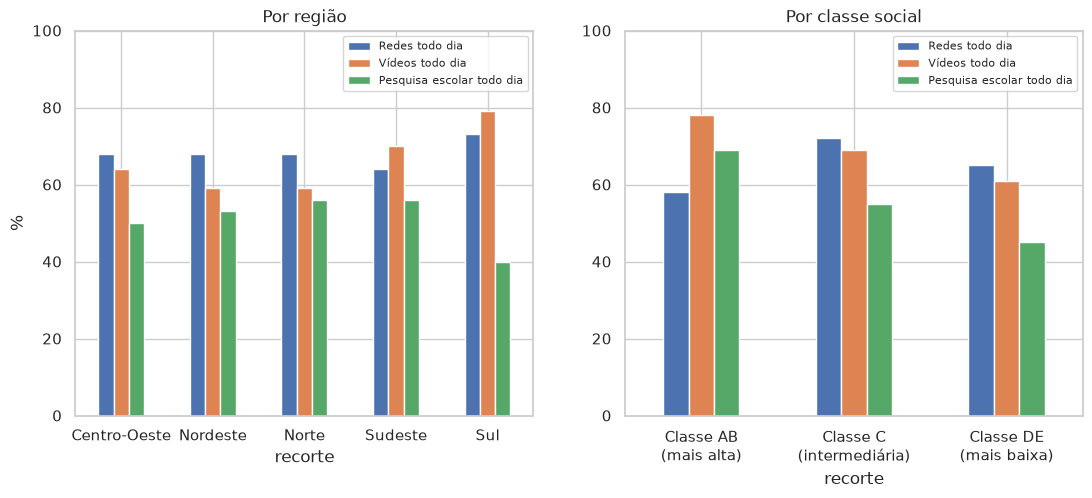

In [ ]:
# AQUI DÁ NOMES MAIS FÁCEIS PRAS COLUNAS APARECEREM NO GRÁFICO
novos_nomes = {'redes_diario': 'Redes todo dia', 'videos_diario': 'Vídeos todo dia', 'escolar_diario': 'Pesquisa escolar todo dia'}
tab_regiao = regiao[['redes_diario', 'videos_diario', 'escolar_diario']].rename(columns=novos_nomes)
tab_classe = classe[['redes_diario', 'videos_diario', 'escolar_diario']].rename(columns=novos_nomes)
# AQUI QUEBRA O NOME DA CLASSE EM DUAS LINHAS PRA NÃO ENCAVALAR NO GRÁFICO
tab_classe.index = tab_classe.index.str.replace(' (', '\n(')

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
tab_regiao.plot(kind='bar', ax=ax[0])
ax[0].set_title('Por região')
ax[0].set_ylabel('%')
ax[0].set_ylim(0, 100)
ax[0].tick_params(axis='x', rotation=0)
ax[0].legend(fontsize=8)
tab_classe.plot(kind='bar', ax=ax[1])
ax[1].set_title('Por classe social')
ax[1].set_ylim(0, 100)
ax[1].tick_params(axis='x', rotation=0)
ax[1].legend(fontsize=8)
plt.show()

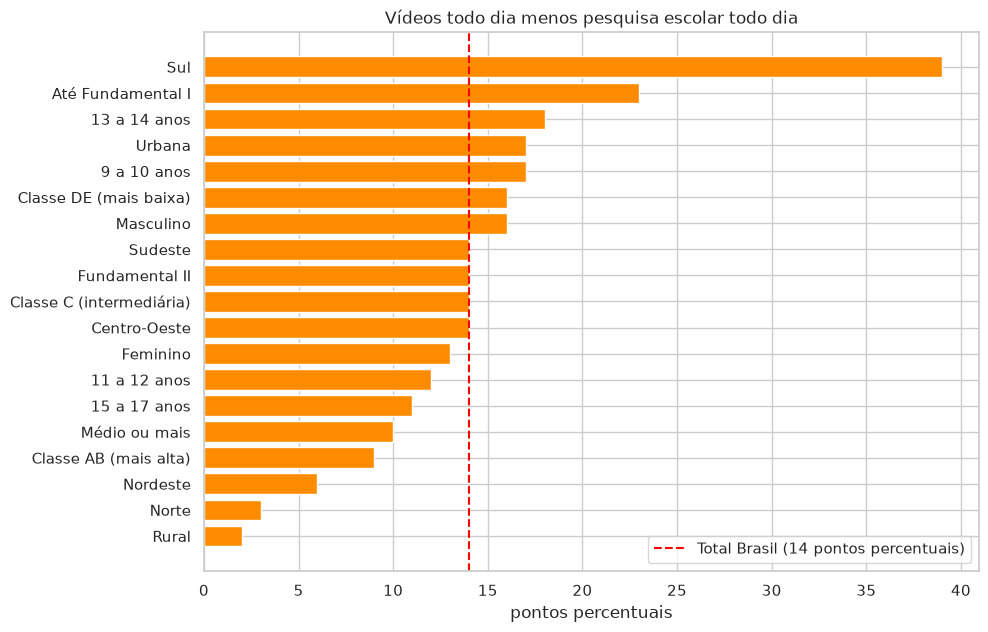

In [ ]:
# AQUI MOSTRA A DIFERENÇA ENTRE VÍDEOS E PESQUISA ESCOLAR EM CADA GRUPO
p3 = grupos.sort_values('gap_videos_menos_escolar')

plt.figure(figsize=(10, 7))
plt.barh(p3['recorte'], p3['gap_videos_menos_escolar'], color='darkorange')
plt.axvline(total['gap_videos_menos_escolar'], color='red', linestyle='--', label='Total Brasil (14 pontos percentuais)')
plt.xlabel('pontos percentuais')
plt.title('Vídeos todo dia menos pesquisa escolar todo dia')
plt.legend()
plt.show()

No geral, quem vê mais vídeo também pesquisa mais pra escola, porque com a idade tudo aumenta junto. Mas o Sul chama atenção: 79% veem vídeo todo dia e só 40% pesquisam pra escola, uma diferença quase 3 vezes maior que a do Brasil. Já a classe AB (mais alta) pesquisa mais do que usa rede.

### Pergunta 4 - orientação dos pais x uso problemático

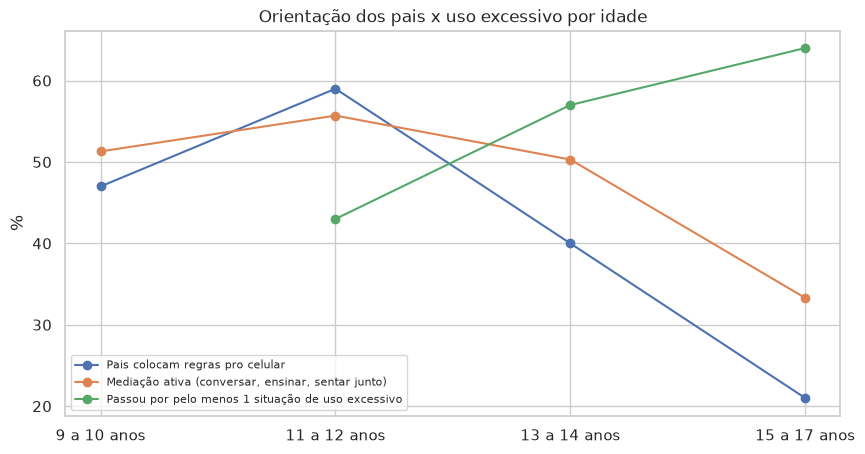

,med_regras_celular,med_ativa_media,g17_ao_menos_uma_aprox
recorte,,,
9 a 10 anos,47.0,51.3,NaN
11 a 12 anos,59.0,55.7,43.0
13 a 14 anos,40.0,50.3,57.0
15 a 17 anos,21.0,33.3,64.0


In [ ]:
# AQUI FAZ O GRÁFICO DA ORIENTAÇÃO DOS PAIS E DO USO EXCESSIVO POR IDADE
plt.plot(ordem_idade, idade['med_regras_celular'], marker='o', label='Pais colocam regras pro celular')
plt.plot(ordem_idade, idade['med_ativa_media'], marker='o', label='Mediação ativa (conversar, ensinar, sentar junto)')
plt.plot(ordem_idade, idade['g17_ao_menos_uma_aprox'], marker='o', label='Passou por pelo menos 1 situação de uso excessivo')
plt.ylabel('%')
plt.title('Orientação dos pais x uso excessivo por idade')
plt.legend(fontsize=8)
plt.show()

idade[['med_regras_celular', 'med_ativa_media', 'g17_ao_menos_uma_aprox']]

Os pais colocam menos regra conforme o filho cresce: 59% aos 11 a 12 anos e só 21% aos 15 a 17. E é bem quando o uso excessivo sobe (de 43% pra 64%). Esses dados são o que os filhos responderam.

### Pergunta 5 - desigualdades socioeconômicas

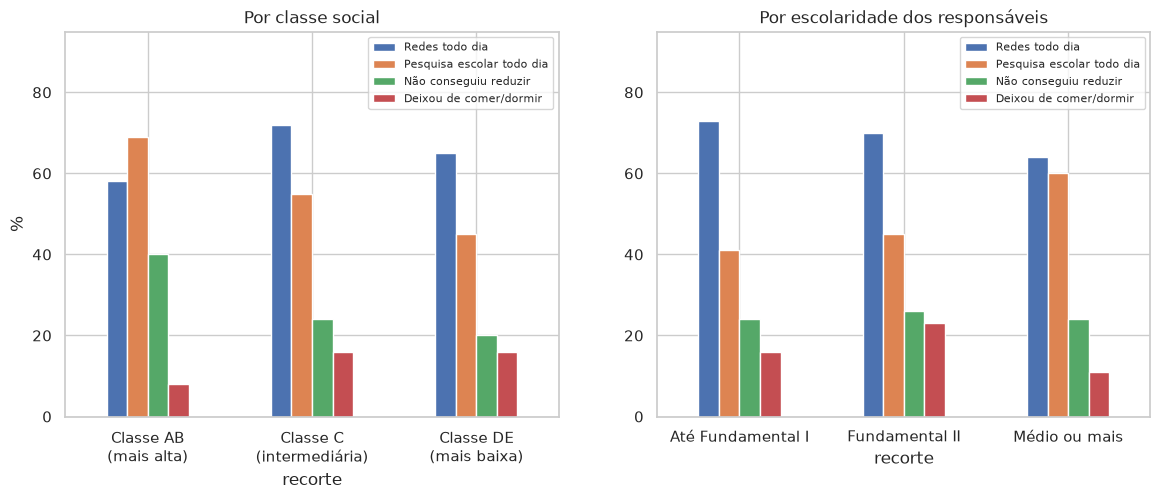

In [ ]:
# AQUI ESCOLHE OS INDICADORES PRA COMPARAR AS CLASSES E A ESCOLARIDADE DOS PAIS
cols_p5 = ['redes_diario', 'escolar_diario', 'g17_nao_conseguiu_reduzir', 'g17_comer_dormir']
nomes_p5 = ['Redes todo dia', 'Pesquisa escolar todo dia', 'Não conseguiu reduzir', 'Deixou de comer/dormir']

tab = classe[cols_p5].copy()
tab.columns = nomes_p5
tab.index = tab.index.str.replace(' (', '\n(')
tab2 = escolaridade[cols_p5].copy()
tab2.columns = nomes_p5

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
tab.plot(kind='bar', ax=ax[0])
ax[0].set_title('Por classe social')
ax[0].set_ylabel('%')
ax[0].tick_params(axis='x', rotation=0)
ax[0].legend(fontsize=8)
ax[0].set_ylim(0, 95)
tab2.plot(kind='bar', ax=ax[1])
ax[1].set_title('Por escolaridade dos responsáveis')
ax[1].tick_params(axis='x', rotation=0)
ax[1].legend(fontsize=8)
ax[1].set_ylim(0, 95)
plt.show()

Todas as classes têm problema, mas de jeito diferente. Na classe AB (mais alta) é falta de controle, mas é a que mais usa a internet pra estudar (69%) e quase não deixa de comer ou dormir (8%). Nas classes C (intermediária) e DE (mais baixa) é o contrário: mais perda de sono e refeição (16%) e menos pesquisa pra escola. Ou seja, a classe muda o tipo de problema, não se ele existe.

### As correlações fazem sentido?
A idade faz quase tudo subir junto, então testamos as correlações com todos os grupos e depois sem os grupos de idade. Se some quando tira a idade, era só efeito da idade.

In [ ]:
# AQUI FICAM OS PARES QUE A GENTE QUER TESTAR
testes = [['redes_diario', 'g17_menos_tempo_licao'],
          ['videos_diario', 'g17_menos_tempo_licao'],
          ['redes_diario', 'escolar_diario'],
          ['videos_diario', 'escolar_diario'],
          ['med_restritiva_media', 'g17_indice_medio_5itens'],
          ['med_ativa_media', 'g17_indice_medio_5itens']]

# AQUI TIRA OS GRUPOS DE IDADE PRA VER SE A CORRELAÇÃO CONTINUA
sem_idade = grupos[grupos['recorte_tipo'] != 'Faixa etária']

# AQUI CALCULA A CORRELAÇÃO DE SPEARMAN COM E SEM A IDADE
resultado = []
for x, y in testes:
    a = grupos.dropna(subset=[x, y])
    b = sem_idade.dropna(subset=[x, y])
    corr_a, pval_a = spearmanr(a[x], a[y])
    corr_b, pval_b = spearmanr(b[x], b[y])
    resultado.append([x, y, round(corr_a, 2), round(pval_a, 3), round(corr_b, 2), round(pval_b, 3)])

resultado = pd.DataFrame(resultado, columns=['x', 'y', 'corr todos', 'p todos', 'corr sem idade', 'p sem idade'])
resultado

,x,y,corr todos,p todos,corr sem idade,p sem idade
0,redes_diario,g17_menos_tempo_licao,0.43,0.078,0.25,0.363
1,videos_diario,g17_menos_tempo_licao,0.57,0.014,0.68,0.005
2,redes_diario,escolar_diario,-0.04,0.886,-0.48,0.073
3,videos_diario,escolar_diario,0.54,0.018,0.29,0.287
4,med_restritiva_media,g17_indice_medio_5itens,-0.08,0.767,0.33,0.299
5,med_ativa_media,g17_indice_medio_5itens,-0.34,0.209,-0.08,0.797


Só vídeo x menos tempo/lição continuou forte sem a idade (0,68). Redes x lição caiu de 0,43 pra 0,25, vídeo x pesquisa escolar caiu de 0,54 pra 0,29, e as de mediação dos pais não deram nada.
Uma coisa curiosa: sem a idade, redes x pesquisa escolar ficou -0,48, ou seja, grupos que usam mais rede pesquisam um pouco menos. Mas não passou no teste (p = 0,07), então é só uma pista.
O achado mais firme é o do vídeo, e o resto a gente trata como tendência. Como os grupos se misturam, o p serve só de referência.

### K-Means
Juntamos os grupos parecidos. 9 a 10 anos ficou de fora porque não tem G17.

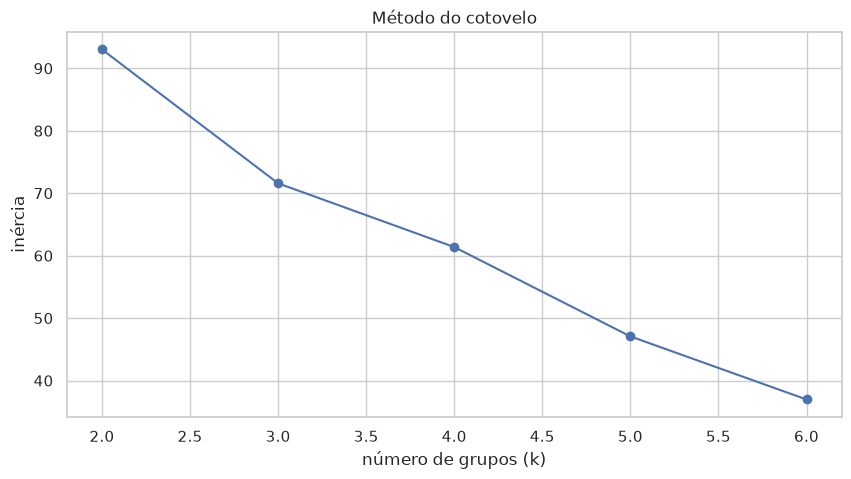

In [ ]:
cols_cluster = ['redes_diario', 'videos_diario', 'escolar_diario', 'g17_comer_dormir',
                'g17_sem_interesse', 'g17_menos_tempo_licao', 'g17_nao_conseguiu_reduzir']

# AQUI DEIXA TODAS AS COLUNAS NA MESMA ESCALA PRO K-MEANS
base_cluster = grupos.dropna(subset=cols_cluster).copy()
X = StandardScaler().fit_transform(base_cluster[cols_cluster])

# AQUI TESTA DE 2 A 6 GRUPOS PRA ESCOLHER O NÚMERO (MÉTODO DO COTOVELO)
inercia = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X)
    inercia.append(km.inertia_)

plt.plot(range(2, 7), inercia, marker='o')
plt.xlabel('número de grupos (k)')
plt.ylabel('inércia')
plt.title('Método do cotovelo')
plt.show()

In [ ]:
# AQUI RODA O K-MEANS COM 3 GRUPOS
km = KMeans(n_clusters=3, random_state=42, n_init=10)
base_cluster['cluster'] = km.fit_predict(X)
media_cluster = base_cluster.groupby('cluster')[cols_cluster].mean()

# AQUI DÁ NOME PRA CADA PERFIL OLHANDO AS MÉDIAS
nomes = {}
for c in media_cluster.index:
    if media_cluster.loc[c, 'g17_nao_conseguiu_reduzir'] > 35:
        nomes[c] = 'Estuda mais, mas perde o controle'
    elif media_cluster.loc[c, 'g17_menos_tempo_licao'] > 25:
        nomes[c] = 'Uso intenso com prejuízo'
    else:
        nomes[c] = 'Uso moderado'

base_cluster['perfil'] = base_cluster['cluster'].map(nomes)
print(media_cluster.round(1))
base_cluster[['recorte_tipo', 'recorte', 'perfil']].sort_values('perfil')

         redes_diario  videos_diario  escolar_diario  g17_comer_dormir  \
cluster                                                                  
0                65.6           62.1            51.8              14.2   
1                58.0           78.0            69.0               8.0   
2                73.9           70.8            52.1              15.6   

         g17_sem_interesse  g17_menos_tempo_licao  g17_nao_conseguiu_reduzir  
cluster                                                                       
0                     20.1                   16.1                       21.2  
1                     23.0                   23.0                       40.0  
2                     23.1                   27.6                       26.0  


,recorte_tipo,recorte,perfil
8,Classe social,Classe AB (mais alta),"Estuda mais, mas perde o controle"
9,Classe social,Classe C (intermediária),Uso intenso com prejuízo
2,Área,Urbana,Uso intenso com prejuízo
17,Escolaridade dos responsáveis,Até Fundamental I,Uso intenso com prejuízo
15,Faixa etária,15 a 17 anos,Uso intenso com prejuízo
14,Faixa etária,13 a 14 anos,Uso intenso com prejuízo
6,Região,Sudeste,Uso intenso com prejuízo
7,Região,Sul,Uso intenso com prejuízo
11,Sexo,Feminino,Uso intenso com prejuízo
13,Faixa etária,11 a 12 anos,Uso moderado


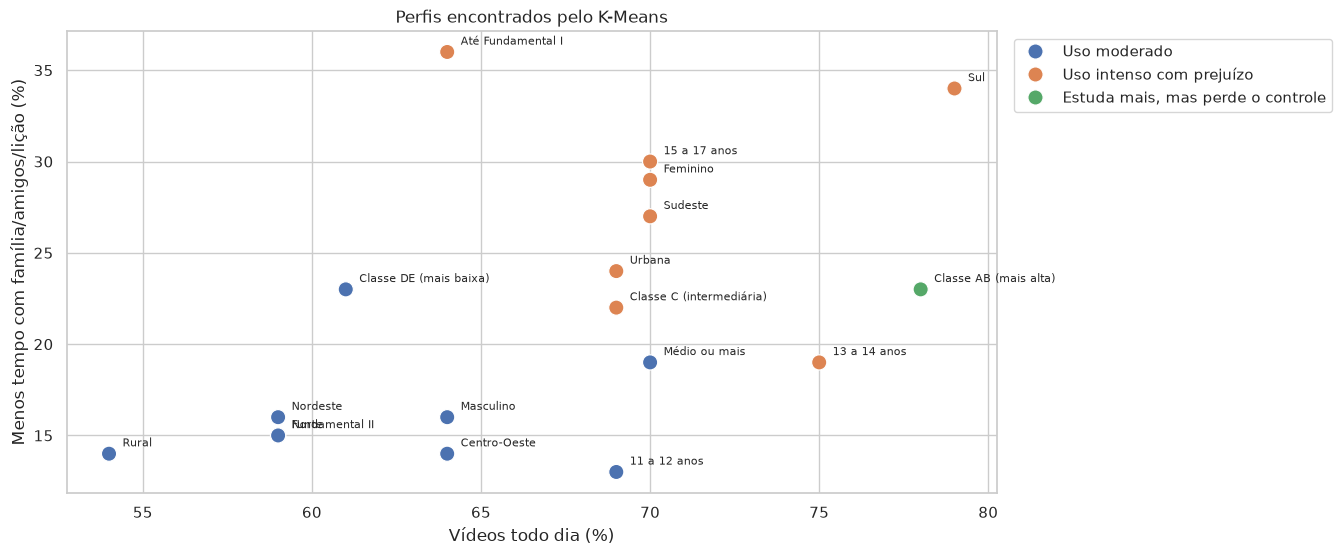

In [ ]:
# AQUI MOSTRA OS PERFIS NO GRÁFICO COM O NOME DE CADA GRUPO
plt.figure(figsize=(12, 6))
sns.scatterplot(data=base_cluster, x='videos_diario', y='g17_menos_tempo_licao', hue='perfil', s=120)
for i, linha in base_cluster.iterrows():
    plt.text(linha['videos_diario'] + 0.4, linha['g17_menos_tempo_licao'] + 0.4, linha['recorte'], fontsize=8)
plt.xlabel('Vídeos todo dia (%)')
plt.ylabel('Menos tempo com família/amigos/lição (%)')
plt.title('Perfis encontrados pelo K-Means')
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.show()

Ficaram 3 perfis:
- uso intenso com prejuízo: Sul, Sudeste, urbana, meninas, 13 a 17 anos, classe C (intermediária) e pais até Fundamental I
- uso moderado: Norte, Nordeste, Centro-Oeste, rural, meninos, 11 a 12 anos, classe DE (mais baixa) e pais com Fundamental II ou Médio
- estuda mais, mas perde o controle: só a classe AB (mais alta)

O primeiro é o que mais precisa de atenção.

### Conclusão
A idade é o que mais pesa: o uso e o prejuízo aumentam e os pais orientam menos. O achado mais firme é que ver vídeo todo dia anda junto com perder tempo de lição, mesmo tirando a idade. A classe social muda o tipo de problema: na AB (mais alta) é controle, e na C (intermediária) e DE (mais baixa) é sono e menos estudo. Não deu pra dizer que mais regra dos pais diminui o uso excessivo. Tudo isso é associação, pra confirmar teria que usar os microdados.

## Base limpa
Salvamos a base limpa, que é a mesma que está na aba Base do dashboard em Excel.

In [ ]:
# AQUI DEFINE A ORDEM DOS GRUPOS IGUAL NO DASHBOARD
ordem = {'Total': 0, 'Urbana': 1, 'Rural': 2,
         'Norte': 1, 'Nordeste': 2, 'Centro-Oeste': 3, 'Sudeste': 4, 'Sul': 5,
         'Classe AB (mais alta)': 1, 'Classe C (intermediária)': 2, 'Classe DE (mais baixa)': 3,
         'Feminino': 1, 'Masculino': 2,
         '9 a 10 anos': 1, '11 a 12 anos': 2, '13 a 14 anos': 3, '15 a 17 anos': 4,
         'Até Fundamental I': 1, 'Fundamental II': 2, 'Médio ou mais': 3}
ordem_tipo = {'Total': 0, 'Região': 1, 'Classe social': 2, 'Sexo': 3, 'Faixa etária': 4, 'Área': 5,
              'Escolaridade dos responsáveis': 6}

# AQUI COLOCA A COLUNA DE ORDEM E ORDENA A BASE
base_limpa = df.copy()
base_limpa.insert(2, 'ordem', base_limpa['recorte'].map(ordem))
base_limpa['ordem_tipo'] = base_limpa['recorte_tipo'].map(ordem_tipo)
base_limpa = base_limpa.sort_values(['ordem_tipo', 'ordem']).drop(columns='ordem_tipo')

# AQUI SALVA A BASE LIMPA EM EXCEL
base_limpa.to_excel('base_limpa.xlsx', index=False)
print(base_limpa.shape)
print('salvo')

(20, 39)
salvo
